In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler

def process_categorical_data():
	# Starting with classification dataset
	class_df = pd.read_csv("diabetes_data_upload.csv", index_col=False)
	# class_df.head()
	#class_df.info()
	# No Null values are in this dataset
	# print(class_df.isnull().sum())

	# Visualise and then handle outliers
	# Our diabetes dataset contains symptoms so uncommon symptoms may not indicate the condition

	features = class_df.iloc[:,1:]
	fig,axes = plt.subplots(5,4,figsize=(20,26))

	sns.boxplot(x="Gender", y="Age", data=class_df)
	# sns.countplot(x="Gender", data=class_df)
	for	feature, ax in zip(features, axes.flat):
		sns.countplot(x=feature, data=class_df, ax=ax, hue="Gender")

	plt.show
	# Seems that there are 2 outliers for age, since we only care about categorical data we will drop this column

	class_df = class_df.drop(columns="Age")
	# Chose to One hot encode instead of ordinal because it suits our binary data better
	cat_encoder = OneHotEncoder(sparse_output=False)
	# We are only going to encode our feature because our label needs to be a 1d array
	cdf_encoded = cat_encoder.fit_transform(class_df.iloc[:,1:])


	encoded_df_diabetes = pd.DataFrame( # recreate the df with new column names
		cdf_encoded,
		columns=cat_encoder.get_feature_names_out(),
		index=class_df.index)

	encoded_df_diabetes = pd.concat([class_df["Gender"], encoded_df_diabetes], axis=1)
	# You don't need to convert the label actually xd
	#https://www.geeksforgeeks.org/machine-learning/ml-one-hot-encoding/

	return encoded_df_diabetes

process_categorical_data()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0.297521,0.413333,0.000000,0.019939,0.111296,0.034722,0.064516,0.206092,0.612403,0.191011,0.202899,5
1,0.330579,0.533333,0.000000,0.030675,0.147841,0.083333,0.140553,0.186813,0.372093,0.258427,0.260870,5
2,0.330579,0.453333,0.024096,0.026074,0.137874,0.048611,0.110599,0.190669,0.418605,0.241573,0.260870,5
3,0.611570,0.133333,0.337349,0.019939,0.109635,0.055556,0.124424,0.209948,0.341085,0.202247,0.260870,6
4,0.297521,0.413333,0.000000,0.019939,0.111296,0.034722,0.064516,0.206092,0.612403,0.191011,0.202899,5
...,...,...,...,...,...,...,...,...,...,...,...,...
6492,0.198347,0.086667,0.174699,0.015337,0.049834,0.079861,0.198157,0.077694,0.426357,0.157303,0.463768,6
6493,0.231405,0.160000,0.216867,0.113497,0.063123,0.194444,0.373272,0.150183,0.333333,0.134831,0.231884,5
6494,0.223140,0.106667,0.114458,0.009202,0.053156,0.100694,0.241935,0.104685,0.209302,0.134831,0.202899,6
6495,0.140496,0.140000,0.180723,0.007669,0.021595,0.065972,0.239631,0.030461,0.480620,0.089888,0.695652,7


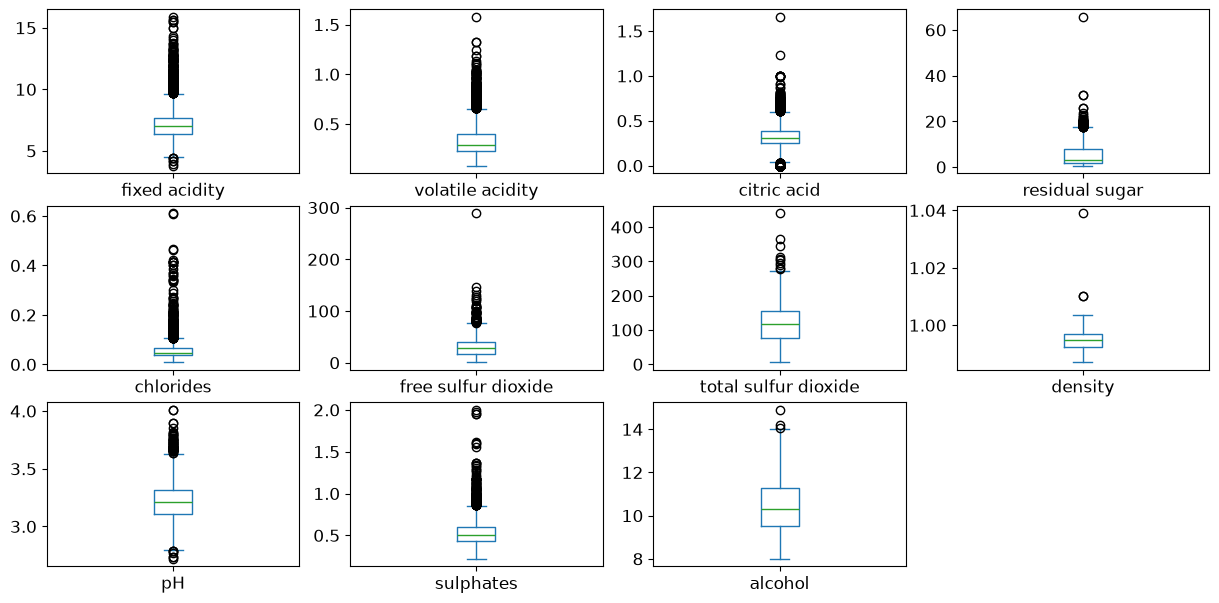

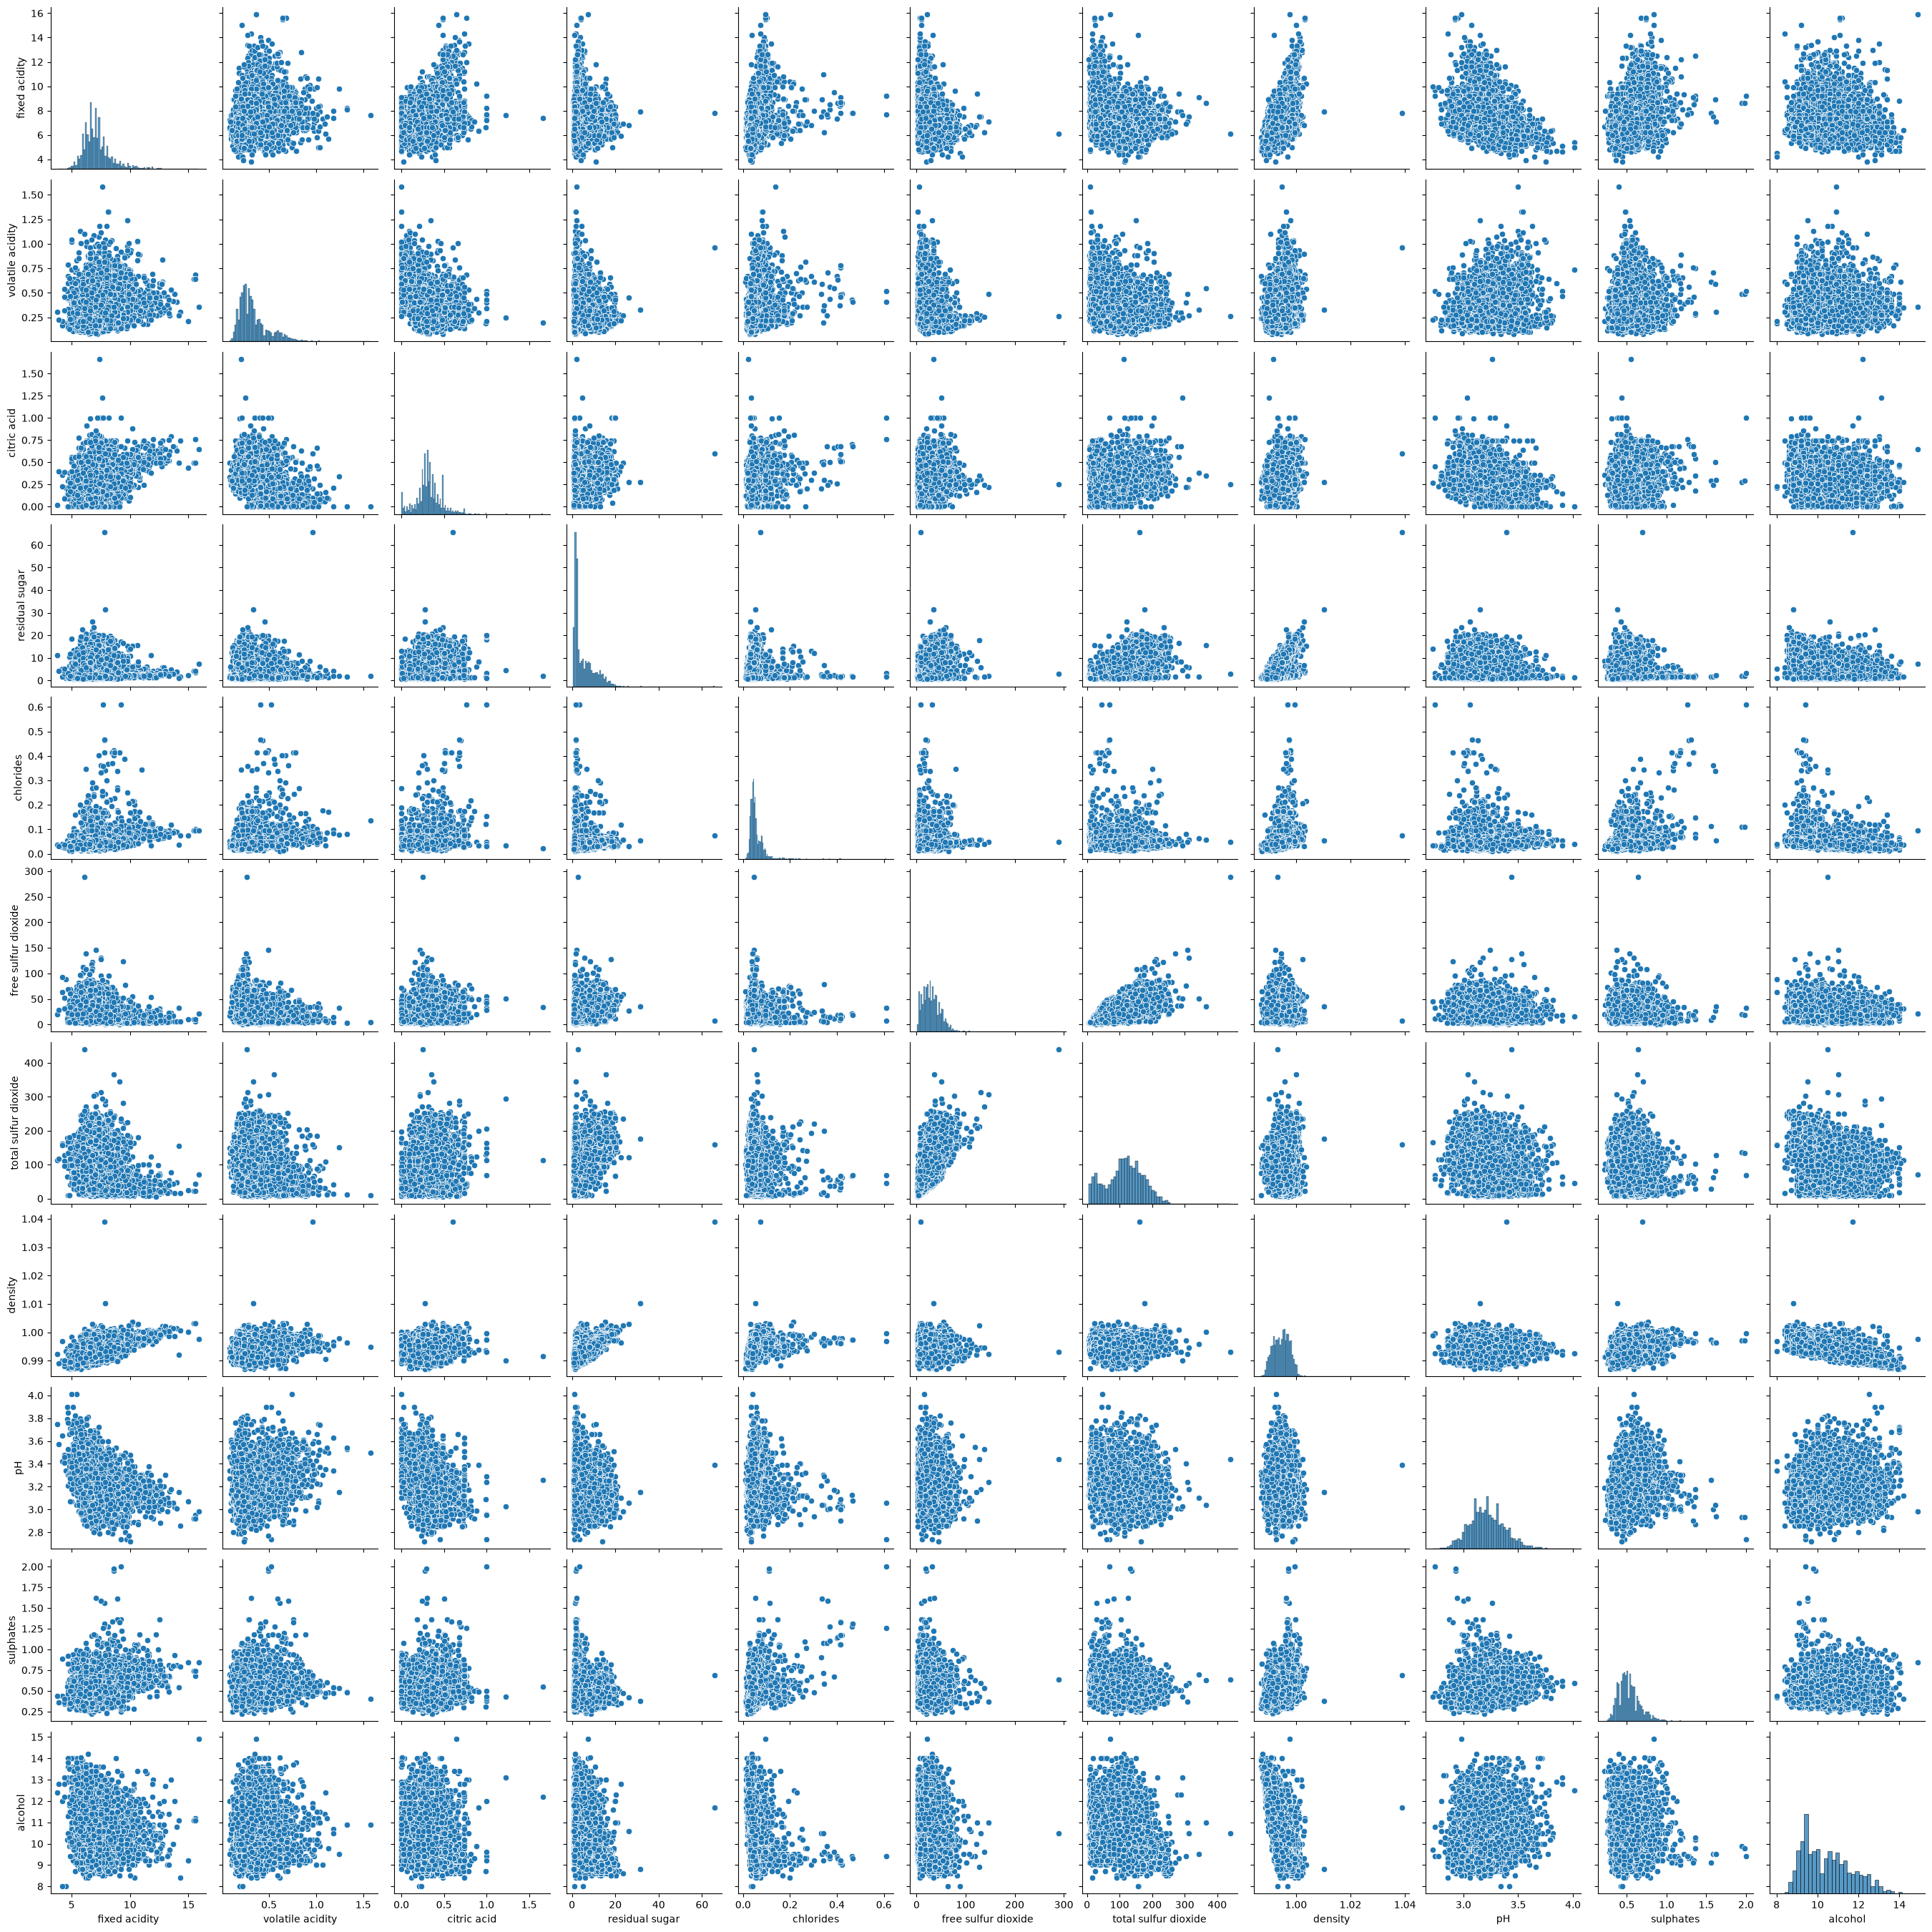

In [40]:
def process_continuous_data():
	# read the dataset
	cont_red_df = pd.read_csv("winequality-red.csv", index_col=False, sep=";")
	cont_white_df = pd.read_csv("winequality-white.csv", index_col=False, sep=";")

	cont_wine_df = pd.concat([cont_red_df, cont_white_df], ignore_index = True, axis=0)

	# Look for outliers (theres no missing data btw)

	data_mean = cont_wine_df.iloc[:,:11]
	data_mean.plot(kind='box', subplots=True, layout=(8,4), sharex=False,
	sharey=False, fontsize=12, figsize=(15,20));

	sns.pairplot(cont_wine_df[list(cont_wine_df.columns[:11])]);
	# Normalise to resize values to the same scale 
	# if using min max normalisation then it is better to remove outliers first
	scaler = MinMaxScaler()
	features_wine = list(cont_wine_df)
	features_wine.pop()

	X_normalised = cont_wine_df.iloc[:,:11]
	X_normalised[features_wine] = scaler.fit_transform(X_normalised[features_wine])

	# Combine back with y target
	processed_wine_df = pd.concat([X_normalised, cont_wine_df["quality"]], axis=1)

	return processed_wine_df
process_continuous_data()
